In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from scipy.cluster.hierarchy import linkage, dendrogram

In [25]:
df = pd.read_csv(r"D:\ML Datasets\sales_data_sample.csv",encoding="latin1")
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [27]:
df.isnull().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [28]:
X = df[["SALES","QUANTITYORDERED"]]
X.head()

,SALES,QUANTITYORDERED
0,2871.00,30
1,2765.90,34
2,3884.34,41
3,3746.70,45
4,5205.27,49


In [29]:
sc = StandardScaler()
X_scale = sc.fit_transform(X)

In [30]:
X_scale[:5]

array([[-0.37082523, -0.52289086],
       [-0.42789707, -0.11220131],
       [ 0.17944282,  0.60650538],
       [ 0.10470098,  1.01719493],
       [ 0.89673966,  1.42788447]])

In [31]:
wcss = []

In [32]:
for i in range(1,11):
    Kmeans = KMeans(n_clusters = i, n_init =10, random_state=42)
    Kmeans.fit(X_scale)
    wcss.append(Kmeans.inertia_)

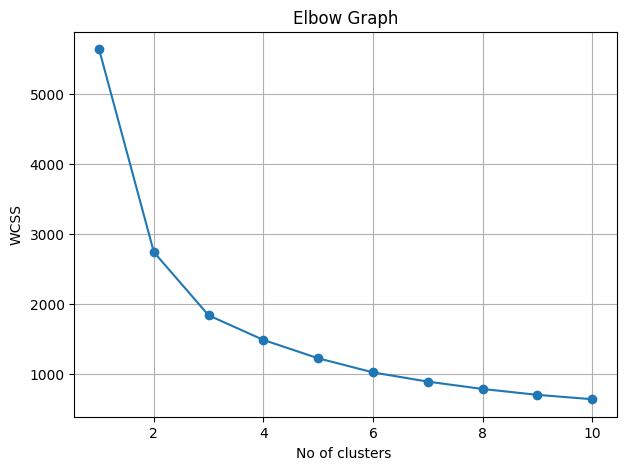

In [33]:
plt.figure(figsize=(7,5))
plt.plot(range(1,11), wcss, marker="o")
plt.title("Elbow Graph")
plt.xlabel("No of clusters ")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()

In [34]:
# Here k = 3

kmeans = KMeans(n_clusters=3, n_init=10,random_state=42)
df["KMean_Cluster"]=kmeans.fit_predict(X_scale)

In [35]:
df[["SALES","QUANTITYORDERED","KMean_Cluster"]].head(10)

,SALES,QUANTITYORDERED,KMean_Cluster
0,2871.00,30,1
1,2765.90,34,2
2,3884.34,41,2
3,3746.70,45,2
4,5205.27,49,0
5,3479.76,36,2
6,2497.77,29,1
7,5512.32,48,0
8,2168.54,22,1
9,4708.44,41,2


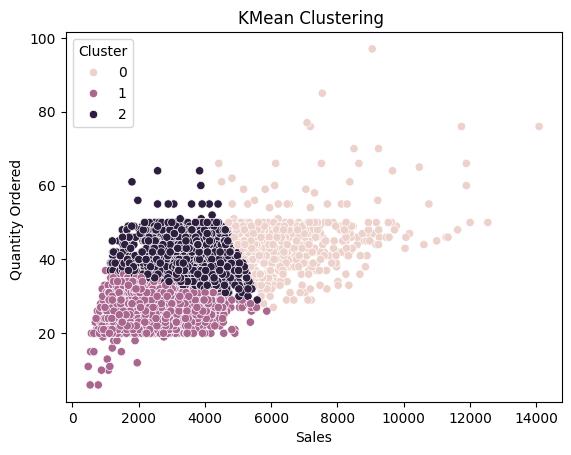

In [36]:
# Visualize them 

sns.scatterplot(x= df["SALES"],y = df["QUANTITYORDERED"], hue= df["KMean_Cluster"])
plt.title("KMean Clustering ")
plt.xlabel("Sales")
plt.ylabel("Quantity Ordered ")
plt.legend(title="Cluster")
plt.show()


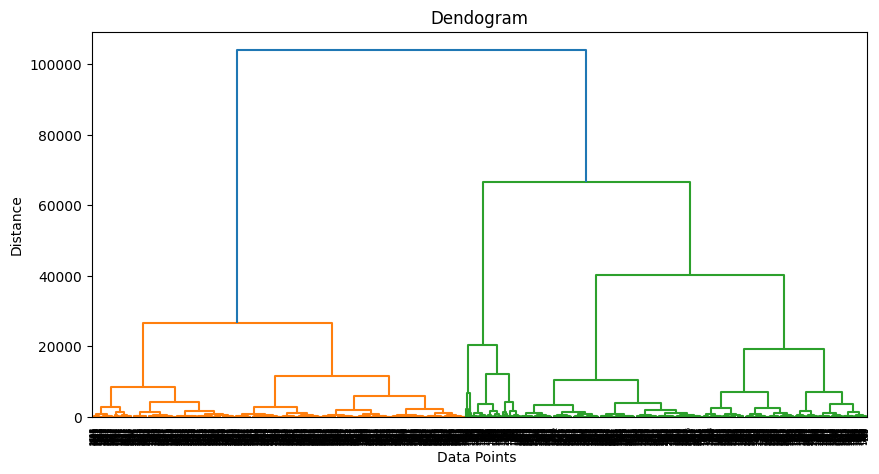

In [37]:
#Hierarchical Clustering

linked = linkage(X,method="ward")
plt.figure(figsize=(10,5))
dendrogram(linked)
plt.title("Dendogram")
plt.xlabel("Data Points ")
plt.ylabel("Distance")
plt.show()

In [49]:
hc = AgglomerativeClustering()
clusters = hc.fit_predict(X)

In [50]:
df["AgglomerativeClustering"] = clusters

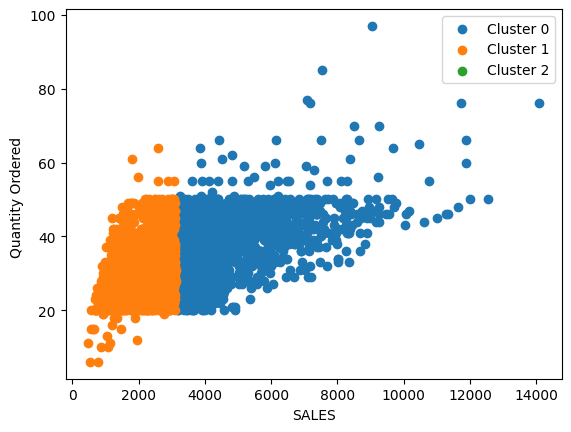

In [51]:
for i in range(3):
    plt.scatter(
        X.values[clusters == i, 0],
        X.values[clusters == i, 1],
        label="Cluster " + str(i)
    )
plt.xlabel("SALES")
plt.ylabel("Quantity Ordered ")
plt.legend()
plt.show()

In [52]:
print(type(X))

<class 'pandas.core.frame.DataFrame'>
